### **TUGAS PENGOLAHAN CITRA DIGITAL**

#### **Analisis Metadata dan Data Gambar Menggunakan Python**

#### **Nama** : Shela Rahma Fitri
#### **NIM**  :24260012
#### **Semester** : 5

In [59]:
from PIL import Image, ExifTags
from IPython.display import display, HTML
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

## **1. Library yang Digunakan**

Pada analisis citra digital ini, digunakan beberapa library Python untuk membantu membaca gambar, mengakses metadata, mengolah data pixel, menampilkan visualisasi, dan menyusun data hasil analisis.

Library yang digunakan beserta fungsinya adalah sebagai berikut:
- **PIL (Pillow)** Membuka, mengolah gambar, dan membaca metadata EXIF.
- **NumPy (`numpy`)** Mengolah gambar menjadi array dan menganalisis nilai pixel.
- **Matplotlib (`matplotlib.pyplot`)** Menampilkan gambar dan visualisasi hasil analisis.
- **Pandas (`pandas`)** Menyusun hasil analisis dalam bentuk tabel.
- **OS (`os`)**  Mengakses informasi file dan memeriksa keberadaan file gambar.

Dengan menggunakan library tersebut, proses analisis citra digital dapat dilakukan secara lebih terstruktur, mulai dari membaca informasi gambar hingga mengamati data pixel dan merekonstruksi gambar.

## **2. Membaca Dan Menampilkan Citra**

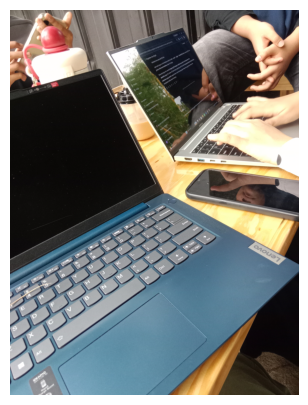

In [60]:
# Membuka file citra asli
image = Image.open("foto/foto.jpg")

# Menampilkan citra dengan ukuran tampilan lebih kecil
plt.figure(figsize=(4, 5))
plt.imshow(image)
plt.axis("off")
plt.show()

### Penjelasan Kode

- `Image.open("foto/foto.jpg")` digunakan untuk membuka dan membaca file foto asli dari folder `foto`.
- `image` merupakan variabel yang menyimpan citra asli yang telah dibaca oleh Python.
- `plt.figure(figsize=(4, 5))` digunakan untuk mengatur ukuran tampilan gambar pada notebook agar tidak terlalu besar.
- `plt.imshow(image)` digunakan untuk menampilkan citra yang tersimpan pada variabel `image`.
- `plt.axis("off")` digunakan untuk menghilangkan sumbu koordinat agar tampilan foto lebih rapi.
- `plt.show()` digunakan untuk menampilkan hasil visualisasi pada notebook.

Pengaturan `figsize` hanya memengaruhi ukuran tampilan gambar pada notebook dan tidak mengubah ukuran, resolusi, maupun nilai piksel pada file foto asli. Oleh karena itu, foto yang digunakan untuk analisis selanjutnya tetap merupakan foto asli.

## **3. Informasi Dasar Citra**

Setelah citra berhasil dibaca, langkah selanjutnya adalah mengetahui informasi dasar dari file citra yang digunakan. Informasi yang diperiksa meliputi nama file, format citra, ukuran file, resolusi, mode warna, dan jumlah keseluruhan piksel.

Informasi ini digunakan sebagai dasar sebelum dilakukan analisis lebih lanjut terhadap metadata dan data numerik yang terdapat di dalam citra.

In [61]:


# Lokasi file citra
file_path = "foto/foto.jpg"

# Informasi dasar citra
nama_file = os.path.basename(file_path)
format_file = image.format
ukuran_file = os.path.getsize(file_path)
lebar, tinggi = image.size
mode_warna = image.mode
jumlah_pixel = lebar * tinggi

print("Nama file       :", nama_file)
print("Format          :", format_file)
print("Ukuran file     :", ukuran_file, "bytes")
print("Resolusi        :", lebar, "x", tinggi, "pixel")
print("Mode warna      :", mode_warna)
print("Jumlah piksel   :", jumlah_pixel, "pixel")

Nama file       : foto.jpg
Format          : JPEG
Ukuran file     : 3452320 bytes
Resolusi        : 3120 x 4160 pixel
Mode warna      : RGB
Jumlah piksel   : 12979200 pixel


### Penjelasan Kode
- `file_path` menyimpan lokasi file foto yang akan dianalisis.
- `os.path.basename()` digunakan untuk mengambil nama file dari lokasi file.
- `image.format` digunakan untuk mengetahui format citra.
- `os.path.getsize()` digunakan untuk mengetahui ukuran file dalam satuan byte.
- `image.size` digunakan untuk memperoleh lebar dan tinggi citra dalam satuan piksel.
- `image.mode` digunakan untuk mengetahui mode warna citra.
- `lebar * tinggi` digunakan untuk menghitung jumlah keseluruhan piksel pada citra.

Hasil dari tahap ini menunjukkan karakteristik dasar dari file citra yang digunakan. Resolusi menunjukkan jumlah piksel yang menyusun citra, sedangkan mode warna menunjukkan bagaimana informasi warna disimpan. Informasi ini akan digunakan sebagai dasar untuk membongkar data numerik citra pada tahap berikutnya.

### Hasil Informasi Dasar Citra

Berdasarkan hasil pembacaan menggunakan Python, file citra yang digunakan bernama `foto.jpg` dengan format JPEG. Ukuran file citra adalah 3.452.320 byte atau sekitar 3,45 MB.

Citra memiliki resolusi sebesar 3120 × 4160 piksel. Dengan demikian, jumlah keseluruhan piksel pada citra adalah:

3120 × 4160 = 12.979.200 piksel.

Citra menggunakan mode warna RGB, sehingga setiap piksel memiliki tiga komponen warna, yaitu Red (R), Green (G), dan Blue (B). Setiap komponen warna tersebut nantinya dapat direpresentasikan dalam bentuk nilai numerik.

Informasi ini menunjukkan bahwa foto digital sebenarnya tersusun dari jutaan data piksel yang dapat dibaca dan dianalisis oleh komputer.

## **4. Analisis Metadata (EXIF)**

Selain data piksel, sebuah foto digital dapat menyimpan informasi tambahan yang disebut metadata. Salah satu jenis metadata pada file foto adalah EXIF (Exchangeable Image File Format).

Metadata EXIF dapat berisi informasi mengenai proses pengambilan foto, seperti tanggal dan waktu pengambilan, merek dan model kamera, orientasi gambar, ISO, aperture, shutter speed, focal length, flash, serta informasi lokasi berupa GPS jika tersedia.

Pada tahap ini, metadata EXIF dari foto akan dibaca menggunakan Python. Tidak semua foto memiliki seluruh informasi EXIF, sehingga hanya data yang benar-benar tersimpan pada file yang akan ditampilkan.

In [62]:
# Membaca metadata EXIF
exif_data = image.getexif()

# Menampilkan jumlah metadata
print("Jumlah data EXIF:", len(exif_data))

# Menyusun metadata dalam bentuk tabel
data_tabel = []

for tag_id, value in exif_data.items():
    tag_name = ExifTags.TAGS.get(tag_id, tag_id)
    data_tabel.append([tag_name, value])

# Menampilkan tabel metadata
display(pd.DataFrame(data_tabel, columns=["Metadata", "Nilai"]))

Jumlah data EXIF: 14


,Metadata,Nilai
0,ImageWidth,3120
1,ImageLength,4160
2,GPSInfo,1092
3,ResolutionUnit,2
4,ExifOffset,346
5,ImageDescription,                               
6,Make,vivo                           
7,Model,V2204                          
8,Software,MediaTek Camera Application    
9,Orientation,0


## **5. Visualisasi Lokasi Berdasarkan Metadata GPS**

Berdasarkan metadata EXIF, gambar memiliki koordinat GPS sebesar -6.488803 dan 106.730179. Koordinat tersebut dikonversi dari format derajat, menit, dan detik ke derajat desimal, kemudian ditampilkan pada Google Maps.

Hasil pemetaan menunjukkan bahwa titik koordinat berada di sekitar kawasan UNUSIA Kampus B, Pondok Udik, Kabupaten Bogor, Jawa Barat. Hasil ini menunjukkan bahwa metadata GPS dapat digunakan untuk memperkirakan lokasi pengambilan gambar.

Namun, titik koordinat tidak selalu menunjukkan posisi yang benar-benar tepat karena akurasi GPS dapat dipengaruhi oleh kondisi sinyal dan lingkungan saat foto diambil.

In [63]:
# Membaca isi metadata GPS
exif_data = image.getexif()
gps_data = exif_data.get_ifd(ExifTags.IFD.GPSInfo)

if gps_data:
    for tag_id, value in gps_data.items():
        tag_name = ExifTags.GPSTAGS.get(tag_id, tag_id)
        print(f"{tag_name}: {value}")
else:
    print("Data koordinat GPS tidak ditemukan.")

GPSVersionID: b'\x02\x02\x00\x00'
GPSLatitudeRef: S
GPSLatitude: (6.0, 29.0, 19.6904)
GPSLongitudeRef: E
GPSLongitude: (106.0, 43.0, 48.6438)
GPSAltitudeRef: b'\x00'
GPSAltitude: 155.0
GPSTimeStamp: (9.0, 18.0, 23.0)
GPSProcessingMethod: b'ASCII\x00\x00\x00GPS\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00'
GPSDateStamp: 2026:10:06


## **6. Konversi Koordinat GPS dan Visualisasi Lokasi**

In [64]:

# Mengambil koordinat dari metadata GPS
def ke_desimal(dms, arah):
    derajat = float(dms[0])
    menit = float(dms[1])
    detik = float(dms[2])

    hasil = derajat + menit / 60 + detik / 3600

    if arah in ["S", "W"]:
        hasil = -hasil

    return hasil

gps = image.getexif().get_ifd(ExifTags.IFD.GPSInfo)

if gps and 2 in gps and 4 in gps:
    lintang = ke_desimal(
        gps[2], gps.get(1, "N")
    )
    bujur = ke_desimal(
        gps[4], gps.get(3, "E")
    )

    # Membuat tautan Google Maps
    link_maps = (
        f"https://www.google.com/maps?q={lintang},{bujur}"
    )

    # Menampilkan tabel koordinat
    tabel_gps = pd.DataFrame({
        "Informasi": [
            "Latitude (Lintang)",
            "Longitude (Bujur)",
            "Koordinat Desimal"
        ],
        "Nilai": [
            f"{lintang:.6f}°",
            f"{bujur:.6f}°",
            f"{lintang:.6f}, {bujur:.6f}"
        ]
    })

    display(tabel_gps)

    display(HTML(
        f'<a href="{link_maps}" target="_blank">'
        '📍 Buka lokasi di Google Maps</a>'
    ))

    # Peta interaktif (jika folium terpasang)
    try:
        import folium

        peta = folium.Map(
            location=[lintang, bujur],
            zoom_start=16
        )

        folium.Marker(
            [lintang, bujur],
            tooltip="Lokasi dari metadata foto",
            popup=f"Koordinat: {lintang:.6f}, {bujur:.6f}"
        ).add_to(peta)

        display(peta)

    except ImportError:
        print(
            "Peta interaktif belum tersedia. "
            "Gunakan tautan Google Maps di atas."
        )

else:
    print("Koordinat GPS tidak lengkap atau tidak tersedia.")

,Informasi,Nilai
0,Latitude (Lintang),-6.488803°
1,Longitude (Bujur),106.730179°
2,Koordinat Desimal,"-6.488803, 106.730179"


Peta interaktif belum tersedia. Gunakan tautan Google Maps di atas.


## **7. Membuktikan bahwa Gambar Tersusun dari Pixel**

Pada tahap ini, gambar diubah menjadi array NumPy untuk mengetahui struktur data citra digital. Array tersebut digunakan untuk melihat ukuran gambar, jumlah dimensinya, dan jumlah pixel yang menyusun gambar.

Bentuk array menunjukkan tinggi gambar, lebar gambar, dan jumlah kanal warna RGB. Jumlah pixel dihitung dengan mengalikan tinggi gambar dengan lebarnya.

In [65]:
# Mengubah citra menjadi array NumPy
image_array = np.array(image)

# Menampilkan bentuk array citra
print("Bentuk array citra:", image_array.shape)

# Menampilkan jumlah dimensi array
print("Jumlah dimensi:", image_array.ndim)

# Menghitung jumlah piksel dari tinggi × lebar citra
jumlah_pixel = image_array.shape[0] * image_array.shape[1]

print("Perhitungan jumlah piksel:", image_array.shape[0], "×", image_array.shape[1])
print("Jumlah piksel:", jumlah_pixel)

Bentuk array citra: (4160, 3120, 3)
Jumlah dimensi: 3
Perhitungan jumlah piksel: 4160 × 3120
Jumlah piksel: 12979200


### Penjelasan Kode dan Hasil

Variabel `image_array` menyimpan data gambar dalam bentuk array NumPy. Atribut `shape` digunakan untuk mengetahui ukuran array, sedangkan `ndim` menunjukkan jumlah dimensinya. Pada citra RGB, array memiliki tiga dimensi yang mewakili tinggi, lebar, dan kanal warna.

Hasil pengujian menunjukkan bahwa array memiliki bentuk `(4160, 3120, 3)` dengan jumlah dimensi sebanyak 3. Artinya, gambar memiliki tinggi 4160 pixel, lebar 3120 pixel, dan tiga kanal warna, yaitu Red (R), Green (G), dan Blue (B).

Jumlah pixel dihitung dengan mengalikan tinggi dan lebar gambar:

\[
4160 \times 3120 = 12.979.200 \text{ pixel}
\]

Dengan demikian, gambar yang dianalisis tersusun dari 12.979.200 pixel. Setiap pixel menyimpan informasi warna yang membentuk citra digital secara keseluruhan.

## **8. Melihat Nilai Pixel dalam Bentuk Angka**

Setelah mengetahui struktur dan jumlah pixel pada citra, tahap selanjutnya adalah melihat nilai numerik yang menyusun pixel tersebut. Untuk mempermudah pengamatan, diambil 4 × 4 pixel pertama dari citra menggunakan teknik slicing pada array NumPy.

Nilai yang ditampilkan merupakan intensitas warna RGB dari setiap pixel, dengan urutan Red (R), Green (G), dan Blue (B).

In [66]:
# Mengambil 4 × 4 piksel pertama dari citra
pixel_4x4 = image_array[:4, :4]

# Menampilkan nilai piksel
print("Nilai 4 × 4 piksel pertama:")
print(pixel_4x4)

Nilai 4 × 4 piksel pertama:
[[[107  99  88]
  [106  98  87]
  [106  98  87]
  [107  99  88]]

 [[111 103  92]
  [109 101  90]
  [108 100  89]
  [108 100  89]]

 [[110 102  91]
  [109 101  90]
  [110 102  91]
  [110 102  91]]

 [[108 100  89]
  [109 101  90]
  [112 104  93]
  [115 107  96]]]


### Penjelasan Kode

- `image_array[:4, :4]` digunakan untuk mengambil 4 baris dan 4 kolom pertama dari array citra.
- `pixel_4x4` digunakan untuk menyimpan bagian citra berukuran 4 × 4 piksel tersebut.
- `print()` digunakan untuk menampilkan nilai piksel dalam bentuk angka.

Setiap bagian `[R G B]` pada hasil tersebut merupakan satu piksel. Karena citra menggunakan format RGB, setiap piksel memiliki tiga nilai yang menunjukkan intensitas Red, Green, dan Blue.

### Hasil dan Interpretasi

Berdasarkan output, diperoleh nilai RGB dari 16 pixel pertama yang tersusun dalam array berukuran 4 × 4. Setiap pixel memiliki tiga nilai numerik yang masing-masing menunjukkan intensitas warna merah (Red), hijau (Green), dan biru (Blue).

Sebagai contoh, pixel pada koordinat `(0, 0)` memiliki nilai RGB `[107, 99, 88]`. Nilai tersebut menunjukkan intensitas masing-masing kanal warna pada pixel tersebut.

Hasil ini menunjukkan bahwa pixel pada citra digital direpresentasikan oleh data numerik. Kumpulan nilai tersebut menjadi dasar bagi komputer untuk menyimpan dan mengolah informasi warna pada gambar.


## **9. Melihat Representasi RGB Setiap Pixel**

Citra RGB menyimpan informasi warna setiap pixel dalam tiga komponen, yaitu Red (R), Green (G), dan Blue (B). Masing-masing komponen memiliki nilai intensitas dari 0 hingga 255.

Pada tahap sebelumnya telah diambil 4 × 4 piksel pertama dalam bentuk angka. Selanjutnya, setiap nilai piksel tersebut akan dipisahkan menjadi komponen R, G, dan B agar dapat diketahui bagaimana warna pada setiap piksel direpresentasikan oleh komputer.

In [67]:
# Mengambil 4 × 4 piksel pertama
pixel_4x4 = image_array[:4, :4]

# Menampilkan nilai RGB setiap piksel
for baris in range(4):
    for kolom in range(4):
        r, g, b = pixel_4x4[baris, kolom]
        print(f"Pixel ({baris}, {kolom}) → R={r}, G={g}, B={b}")

Pixel (0, 0) → R=107, G=99, B=88
Pixel (0, 1) → R=106, G=98, B=87
Pixel (0, 2) → R=106, G=98, B=87
Pixel (0, 3) → R=107, G=99, B=88
Pixel (1, 0) → R=111, G=103, B=92
Pixel (1, 1) → R=109, G=101, B=90
Pixel (1, 2) → R=108, G=100, B=89
Pixel (1, 3) → R=108, G=100, B=89
Pixel (2, 0) → R=110, G=102, B=91
Pixel (2, 1) → R=109, G=101, B=90
Pixel (2, 2) → R=110, G=102, B=91
Pixel (2, 3) → R=110, G=102, B=91
Pixel (3, 0) → R=108, G=100, B=89
Pixel (3, 1) → R=109, G=101, B=90
Pixel (3, 2) → R=112, G=104, B=93
Pixel (3, 3) → R=115, G=107, B=96


### Penjelasan Kode

- `pixel_4x4 = image_array[:4, :4]` digunakan untuk mengambil 4 × 4 piksel pertama dari citra.

- `for baris in range(4)` digunakan untuk membaca setiap baris dari 4 baris piksel yang diambil.

- `for kolom in range(4)` digunakan untuk membaca setiap kolom dari 4 kolom piksel yang diambil.

- `pixel_4x4[baris, kolom]` digunakan untuk mengambil satu piksel berdasarkan posisi baris dan kolom.

- `r, g, b = pixel_4x4[baris, kolom]` digunakan untuk memisahkan tiga nilai pada satu piksel menjadi kanal Red (R), Green (G), dan Blue (B).

- `print()` digunakan untuk menampilkan posisi piksel beserta nilai RGB-nya.

Setiap piksel pada citra RGB memiliki tiga nilai numerik yang menunjukkan intensitas warna Red, Green, dan Blue. Nilai tersebut berada pada rentang 0 sampai 255, bukan dalam bentuk persentase.

Sebagai contoh, pada piksel `(0, 0)` diperoleh:

`R = 107, G = 99, B = 88`

Artinya, satu piksel tersebut memiliki nilai intensitas Red sebesar 107, Green sebesar 99, dan Blue sebesar 88. Ketiga nilai tersebut secara bersama-sama menentukan warna dari piksel tersebut.

Dengan demikian, satu piksel bukan terdiri dari tiga piksel yang berbeda, tetapi satu piksel memiliki tiga nilai atau kanal warna, yaitu R, G, dan B.

## **10. Mengubah Sebagian Gambar Menjadi Matriks Angka**

Pada tahap sebelumnya, nilai RGB dari setiap pixel telah diamati secara langsung. Pada tahap ini, sebagian citra akan direpresentasikan dalam bentuk matriks angka untuk memperlihatkan susunan nilai pixel berdasarkan posisi baris dan kolom.

Karena ukuran citra asli cukup besar, hanya diambil bagian berukuran 5 × 5 pixel pertama. Setiap elemen pada matriks menyimpan tiga nilai intensitas warna, yaitu Red (R), Green (G), dan Blue (B).

In [68]:
# Mengambil sebagian citra, yaitu 5 × 5 piksel pertama
matriks_5x5 = image_array[:5, :5]

# Menampilkan matriks angka
print("Matriks RGB 5 × 5 piksel:")
print(matriks_5x5)

Matriks RGB 5 × 5 piksel:
[[[107  99  88]
  [106  98  87]
  [106  98  87]
  [107  99  88]
  [107  99  88]]

 [[111 103  92]
  [109 101  90]
  [108 100  89]
  [108 100  89]
  [107  99  88]]

 [[110 102  91]
  [109 101  90]
  [110 102  91]
  [110 102  91]
  [108 100  89]]

 [[108 100  89]
  [109 101  90]
  [112 104  93]
  [115 107  96]
  [114 106  95]]

 [[111 103  92]
  [112 104  93]
  [116 108  97]
  [119 111 100]
  [119 111 100]]]


### Penjelasan Kode dan Hasil

Kode `image_array[:5, :5]` digunakan untuk mengambil lima baris dan lima kolom pertama dari array gambar. Hasilnya berupa potongan data yang berukuran 5 × 5 pixel atau sebanyak 25 pixel.

Setiap elemen dalam matriks mewakili satu pixel pada posisi baris dan kolom tertentu. Karena gambar menggunakan format RGB, setiap elemen menyimpan tiga nilai intensitas warna.

Hasil yang ditampilkan menunjukkan bahwa data pixel tersusun secara teratur mengikuti posisi baris dan kolom. Jika diperhatikan, susunan angka pada matriks menggambarkan bagian kecil dari citra asli dalam bentuk data numerik.

Dengan demikian, matriks dapat digunakan untuk melihat susunan data pixel berdasarkan posisi spasialnya. Pada tahap ini, yang diamati bukan seluruh gambar, melainkan potongan berukuran 5 × 5 pixel agar lebih mudah dipahami.

## **11. Menganalisis Hubungan Pixel, Koordinat, dan warna**

Setiap pixel pada citra digital memiliki posisi yang ditentukan berdasarkan baris dan kolom. Pada setiap posisi tersebut terdapat nilai numerik yang merepresentasikan warna pixel dalam kanal Red (R), Green (G), dan Blue (B).

Pada tahap ini, beberapa koordinat pixel yang berbeda akan diambil untuk mengetahui nilai RGB pada masing-masing posisi. Hasilnya akan disajikan dalam bentuk tabel dan visualisasi warna agar hubungan antara koordinat, nilai numerik, dan warna pixel dapat diamati dengan lebih jelas.

Melalui analisis ini, dapat diketahui bahwa setiap posisi pixel pada citra memiliki data numerik yang digunakan untuk merepresentasikan warna pada posisi tersebut.

,"Koordinat (Baris, Kolom)",Red (R),Green (G),Blue (B),Warna RGB
0,"(0, 0)",107,99,88,"(107, 99, 88)"
1,"(0, 100)",132,122,112,"(132, 122, 112)"
2,"(100, 100)",161,152,147,"(161, 152, 147)"
3,"(200, 200)",112,101,95,"(112, 101, 95)"
4,"(500, 500)",255,254,253,"(255, 254, 253)"


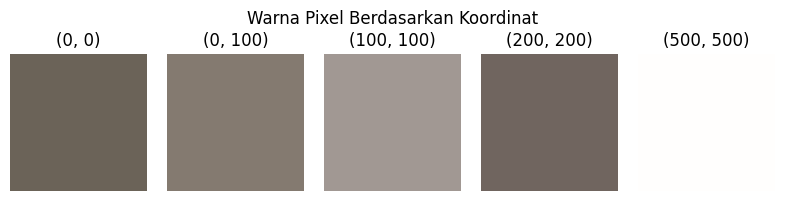

In [ ]:
# Menentukan beberapa koordinat pixel yang akan dianalisis
koordinat_pixel = [
    (0, 0),
    (0, 100),
    (100, 100),
    (200, 200),
    (500, 500)
]

# Menyimpan hasil analisis pixel
data_pixel = []

for baris, kolom in koordinat_pixel:
    # Mengambil nilai RGB berdasarkan koordinat
    r, g, b = image_array[baris, kolom]

    # Menyimpan koordinat dan nilai RGB
    data_pixel.append({
        "Koordinat (Baris, Kolom)": f"({baris}, {kolom})",
        "Red (R)": int(r),
        "Green (G)": int(g),
        "Blue (B)": int(b),
        "Warna RGB": f"({r}, {g}, {b})"
    })

# Menampilkan hasil dalam bentuk tabel

tabel_pixel = pd.DataFrame(data_pixel)
display(tabel_pixel)

# Menampilkan warna dari setiap koordinat pixel
plt.figure(figsize=(8, 2))

for i, (baris, kolom) in enumerate(koordinat_pixel):
    r, g, b = image_array[baris, kolom]

    plt.subplot(1, len(koordinat_pixel), i + 1)
    plt.imshow([[[r, g, b]]])
    plt.title(f"({baris}, {kolom})")
    plt.axis("off")

plt.suptitle("Warna Pixel Berdasarkan Koordinat")
plt.tight_layout()
plt.show()

### Penjelasan Kode

- `koordinat_pixel` berisi daftar posisi pixel yang akan dianalisis. Setiap koordinat ditulis dalam bentuk `(baris, kolom)`.
- `data_pixel = []` digunakan untuk menampung hasil analisis setiap pixel.
- `for baris, kolom in koordinat_pixel` digunakan untuk membaca setiap koordinat secara bergantian.
- `image_array[baris, kolom]` digunakan untuk mengambil nilai pixel pada koordinat yang ditentukan.
- `r, g, b` digunakan untuk memisahkan nilai pixel menjadi kanal Red, Green, dan Blue.
- `data_pixel.append()` digunakan untuk menyimpan koordinat dan nilai RGB ke dalam daftar data.
- `int(r)`, `int(g)`, dan `int(b)` digunakan untuk menampilkan nilai RGB sebagai bilangan bulat.
- `pd.DataFrame(data_pixel)` digunakan untuk menyusun hasil analisis menjadi tabel.
- `display(tabel_pixel)` digunakan untuk menampilkan tabel di notebook.
- `plt.figure(figsize=(8, 2))` digunakan untuk mengatur ukuran area visualisasi warna.
- `plt.subplot()` digunakan untuk menempatkan visualisasi warna setiap pixel secara berdampingan.
- `plt.imshow([[[r, g, b]]])` digunakan untuk menampilkan warna berdasarkan nilai RGB dari koordinat yang sedang dianalisis.
- `plt.title()` digunakan untuk menampilkan koordinat di atas setiap warna.
- `plt.axis("off")` digunakan untuk menyembunyikan sumbu koordinat.
- `plt.suptitle()` memberikan judul pada visualisasi.
- `plt.tight_layout()` digunakan untuk merapikan tata letak visualisasi.
- `plt.show()` digunakan untuk menampilkan hasil visualisasi warna.

### Hasil dan Interpretasi

Tabel menampilkan koordinat pixel beserta nilai Red, Green, dan Blue pada setiap posisi yang dianalisis. Visualisasi warna menunjukkan warna yang dibentuk oleh kombinasi nilai RGB tersebut.

Setiap koordinat menunjukkan posisi pixel yang berbeda pada citra. Oleh karena itu, nilai RGB pada setiap koordinat dapat berbeda, bergantung pada warna bagian gambar di posisi tersebut.

Dengan demikian, analisis ini menunjukkan hubungan antara koordinat pixel, nilai numerik RGB, dan warna yang ditampilkan. Komputer menggunakan posisi serta nilai numerik tersebut untuk merepresentasikan setiap bagian dari citra digital.

## **12. Menandai Letak Pixel pada Foto Asli**

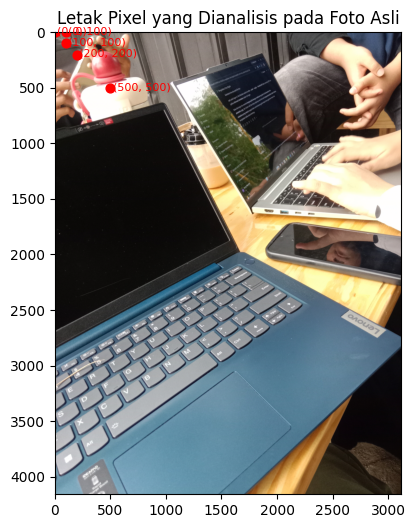

In [70]:
# Menampilkan foto asli dan menandai posisi pixel yang dianalisis
plt.figure(figsize=(8, 6))
plt.imshow(image)

for baris, kolom in koordinat_pixel:
    plt.scatter(kolom, baris, color="red", s=40)
    plt.text(kolom + 20, baris + 20,
             f"({baris}, {kolom})",
             color="red", fontsize=8)

plt.title("Letak Pixel yang Dianalisis pada Foto Asli")
plt.axis("on")
plt.show()

## **13. Membuktikan bahwa Nilai Angka Tersebut Membentuk Kembali Gambar**

Pada tahap sebelumnya, citra digital telah direpresentasikan dalam bentuk array yang berisi nilai numerik setiap pixel. Data tersebut kemudian digunakan untuk membentuk kembali gambar menggunakan fungsi `Image.fromarray()`.

Untuk memastikan bahwa proses rekonstruksi berhasil, data pixel gambar asli dibandingkan dengan data pixel gambar hasil rekonstruksi menggunakan fungsi `np.array_equal()`. Perbandingan ini dilakukan untuk mengetahui apakah kedua gambar memiliki nilai pixel yang sama.

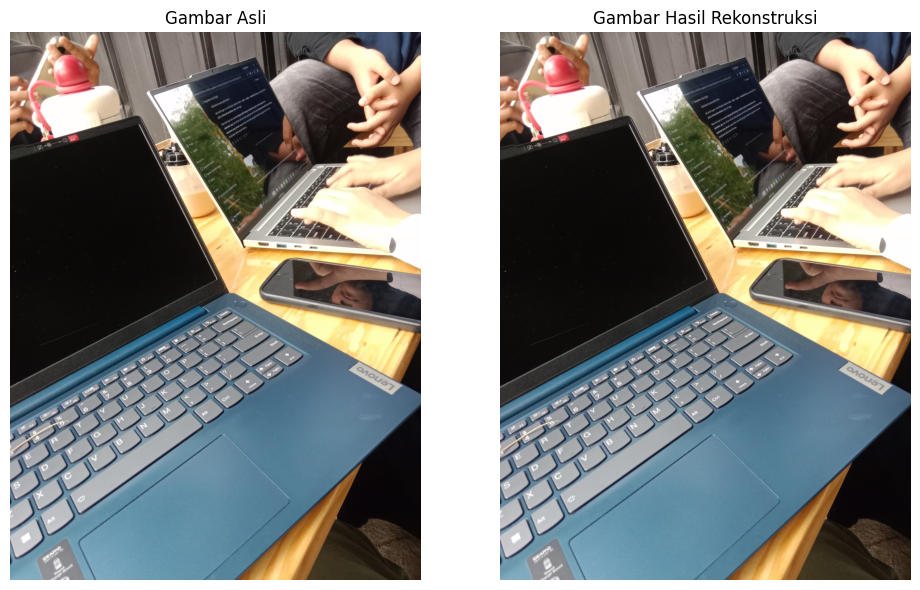

Apakah kedua gambar identik? True
Hasil: Kedua gambar identik.


In [71]:
# Membentuk kembali gambar dari array angka
gambar_rekonstruksi = Image.fromarray(image_array)

# Membandingkan data pixel gambar asli dan hasil rekonstruksi
data_asli = np.array(image)
data_rekonstruksi = np.array(gambar_rekonstruksi)
identik = np.array_equal(data_asli, data_rekonstruksi)

# Menampilkan kedua gambar berdampingan
plt.figure(figsize=(10, 6))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Gambar Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gambar_rekonstruksi)
plt.title("Gambar Hasil Rekonstruksi")
plt.axis("off")

plt.tight_layout()
plt.show()

# Menampilkan hasil perbandingan
print("Apakah kedua gambar identik?", identik)

if identik:
    print("Hasil: Kedua gambar identik.")
else:
    print("Hasil: Kedua gambar tidak identik.")

### Penjelasan Kode dan Hasil

Fungsi `Image.fromarray(image_array)` digunakan untuk membentuk kembali gambar dari array NumPy yang berisi data pixel. Selanjutnya, `np.array_equal(data_asli, data_rekonstruksi)` digunakan untuk membandingkan array gambar asli dengan array gambar hasil rekonstruksi.

Hasil pengujian menunjukkan nilai `True`. Artinya, kedua array memiliki ukuran dan nilai elemen yang sama. Hal ini juga sesuai dengan tampilan kedua gambar yang terlihat identik.

Dengan demikian, proses rekonstruksi berhasil dilakukan tanpa mengubah nilai pixel gambar. Hasil ini membuktikan bahwa data numerik dalam array dapat digunakan untuk membentuk kembali citra digital dengan nilai pixel yang sama seperti gambar aslinya.

## **14. Kesimpulan**

Berdasarkan analisis yang telah dilakukan, citra digital dapat dipelajari melalui informasi dasar gambar, metadata EXIF, serta data numerik yang menyusun setiap pixel. Informasi dasar memberikan gambaran mengenai format, ukuran file, resolusi, mode warna, dan jumlah pixel gambar. Sementara itu, metadata EXIF dapat digunakan untuk mengetahui informasi tambahan yang tersimpan di dalam file gambar.

Melalui NumPy, gambar dapat direpresentasikan dalam bentuk array yang memuat nilai intensitas warna setiap pixel. Pengamatan terhadap sebagian nilai pixel, representasi RGB, matriks angka, serta hubungan antara koordinat dan nilai RGB menunjukkan bahwa setiap pixel memiliki posisi dan data numerik yang membentuk tampilan gambar.

Pengujian rekonstruksi menggunakan `Image.fromarray()` dan perbandingan dengan `np.array_equal()` menghasilkan nilai `True`. Hasil tersebut menunjukkan bahwa gambar hasil rekonstruksi memiliki nilai pixel yang sama dengan gambar asli.

Dengan demikian, analisis ini menunjukkan bahwa citra digital tidak hanya berupa tampilan visual, tetapi juga tersusun dari data numerik yang dapat dibaca, dianalisis, dan digunakan kembali untuk membentuk gambar.